# Assignment 4 (Option 1): Ensemble Learning for Network-Intrusion Detection

This notebook contains all code for Assignment 4. It reuses the ten-class
network-traffic dataset from Assignment 2 and evaluates a **random forest**
against the two Assignment 2 models, **k-nearest neighbours (kNN)** and the
**classification tree**. A class-weighted kNN, implemented here from first
principles, is added as a revision of the Assignment 2 kNN.

**Why a random forest?** A random forest is a bagged ensemble of
classification trees with random feature subsets at each split. The base
learner is the same algorithm as the Assignment 2 tree. The comparison
therefore isolates the contribution of the ensemble mechanism (bootstrap
aggregation and split-level feature randomisation) while the base learner
stays fixed. kNN stays as a dissimilar, distance-based reference point.

## Questions set before evaluation

The tuning experiments are designed to answer the following questions. The
questions were fixed before any test fold was scored.

| ID | Question | Control parameter(s) | Expectation |
|----|----------|----------------------|-------------|
| RQ1 | How does the number of candidate features per split affect performance, and does feature randomisation add anything beyond plain bagging? | `max_features` | An intermediate value is best (strength-correlation trade-off); `max_features = 1.0` (bagging) is worse. |
| RQ2 | Do the member trees of a forest need the same regularisation as a single tree? | `min_samples_leaf` | Forests prefer fully grown trees; a single tree prefers larger leaves. |
| RQ3 | Does class weighting (impurity weights in the tree, class-weighted bootstrap resampling in the forest) improve macro-F1, and for which classes? | `class_weight` | Partial weighting helps separable minority classes but not classes whose feature vectors overlap with other classes. |
| RQ4 | How many trees are needed before performance saturates? | `n_estimators` | Saturation well below 300 trees. |
| RQ5 | Is ordinal encoding of the nominal features at least as good as one-hot encoding for tree-based models? | encoding | Ordinal encoding is at least as good and much cheaper. |
| RQ6 | Does class-weighted voting improve kNN, which has no other mechanism to counter class imbalance? | vote class weight | Partial weighting improves rare-class recall at a small cost in majority-class precision. |
| Main | Does the tuned random forest outperform the Assignment 2 models, significantly, and on which classes? | – | The forest improves macro-F1 mainly through rare-class F1. |

**Running the notebook.** Run top to bottom. The experiment takes several
hours on an 8-core machine, so every outer fold of every model is cached to
`results/folds/`. Rerunning the notebook reloads the cached folds. Setting
the environment variable `A4_QUICK=1` runs a small smoke test on a 15,000-row
subsample and writes to separate output folders.

In [1]:
import os
import pickle
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
)
from sklearn.model_selection import (
    ParameterGrid,
    RepeatedStratifiedKFold,
    train_test_split,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, RobustScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore", message="X does not have valid feature names")

RANDOM_STATE = 441
N_JOBS = 4  # 4 of 8 cores: limits peak memory on a 13 GB laptop; results do not depend on it
QUICK = os.environ.get("A4_QUICK") == "1"

SUFFIX = "_quick" if QUICK else ""
FIG_DIR = Path("figures" + SUFFIX)
TABLE_DIR = Path("tables" + SUFFIX)
CACHE_DIR = Path("results" + SUFFIX) / "folds"
for directory in (FIG_DIR, TABLE_DIR, CACHE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
print("Quick smoke-test mode:", QUICK)

Quick smoke-test mode: False


### Figure style

Figures are sized for one IEEE column (3.5 in) and use a Times-like serif
font at 8-9 pt, close to the report body. Multi-panel figures are saved as
one file per panel, so the report can place them as LaTeX sub-figures with
sub-captions. Each model
keeps one colour and one marker shape in every figure.

In [2]:
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["STIXGeneral", "Times New Roman", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 9,
    "axes.labelsize": 9,
    "axes.titlesize": 9,
    "legend.fontsize": 8,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e4e0",
    "grid.linewidth": 0.5,
    "axes.axisbelow": True,
    "lines.linewidth": 1.4,
    "lines.markersize": 4,
    "legend.frameon": False,
    "figure.dpi": 150,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.02,
    "pdf.fonttype": 42,
})

COLUMN_WIDTH = 3.45
FULL_WIDTH = 7.0

MODEL_ORDER = ["Random forest", "Classification tree", "Class-weighted k-nearest neighbours",
               "k-nearest neighbours"]
# The two kNN variants share one hue (dark and light green) because both are
# versions of one model; marker shapes give a second, colour-free encoding.
MODEL_COLOURS = {
    "Random forest": "#2a78d6",
    "Classification tree": "#eb6834",
    "Class-weighted k-nearest neighbours": "#0f7a55",
    "k-nearest neighbours": "#3cbf8f",
    "Majority baseline": "#8a8a85",
}
MODEL_MARKERS = {
    "Random forest": "o",
    "Classification tree": "s",
    "Class-weighted k-nearest neighbours": "D",
    "k-nearest neighbours": "^",
    "Majority baseline": "x",
}
# Ordinal ramp (light to dark blue) for the three class-weighting schemes.
WEIGHT_ORDER = ["none", "sqrt", "balanced"]
WEIGHT_LABELS = {"none": "No weighting", "sqrt": "Square-root weighting",
                 "balanced": "Balanced weighting"}
WEIGHT_COLOURS = {"none": "#86b6ef", "sqrt": "#2a78d6", "balanced": "#104281"}
WEIGHT_MARKERS = {"none": "o", "sqrt": "s", "balanced": "D"}


def save_figure(fig, name):
    fig.savefig(FIG_DIR / f"{name}.pdf")
    fig.savefig(FIG_DIR / f"{name}.png", dpi=200)

## 1. Data

The dataset is the edited UNSW-NB15 extract supplied for Assignment 2. The
file `networkTraffic.csv` must sit next to this notebook. Missing values are
coded as `?`.

In [3]:
data = pd.read_csv("networkTraffic.csv", na_values="?")
attack_map = pd.read_csv("attack_category_map.csv")
CLASS_NAMES = dict(zip(attack_map["Mapping"], attack_map["Attack Category Name"]))
CLASSES = np.array(sorted(CLASS_NAMES))
N_CLASSES = len(CLASSES)

if QUICK:
    data, _ = train_test_split(
        data, train_size=15_000, stratify=data["attack_cat"],
        random_state=RANDOM_STATE,
    )
    data = data.reset_index(drop=True)

print("Shape:", data.shape)
data.head()

Shape: (257673, 44)


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_srv_src,ct_state_ttl,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat
0,1,0.000011,udp,NaN,INT,2,0,496,0,90909.0902,254,0,180363632.0,0.0,0,0,0.011,0.0,0.0,0.0,0,0,0,0,0.0,0.0,0.0,248,0,0,0,2,2,1,1,1,2,0,0,0,1,2,0,0
1,2,0.000008,udp,NaN,INT,2,0,1762,0,125000.0003,254,0,881000000.0,0.0,0,0,0.008,0.0,0.0,0.0,0,0,0,0,0.0,0.0,0.0,881,0,0,0,2,2,1,1,1,2,0,0,0,1,2,0,0
2,3,0.000005,udp,NaN,INT,2,0,1068,0,200000.0051,254,0,854400000.0,0.0,0,0,0.005,0.0,0.0,0.0,0,0,0,0,0.0,0.0,0.0,534,0,0,0,3,2,1,1,1,3,0,0,0,1,3,0,0
3,4,0.000006,udp,NaN,INT,2,0,900,0,166666.6608,254,0,600000000.0,0.0,0,0,0.006,0.0,0.0,0.0,0,0,0,0,0.0,0.0,0.0,450,0,0,0,3,2,2,2,1,3,0,0,0,2,3,0,0
4,5,0.000010,udp,NaN,INT,2,0,2126,0,100000.0025,254,0,850400000.0,0.0,0,0,0.010,0.0,0.0,0.0,0,0,0,0,0.0,0.0,0.0,1063,0,0,0,3,2,2,2,1,3,0,0,0,2,3,0,0


`id` uniquely identifies each row (shown in Assignment 2) and carries no
information about the traffic, so it is removed before any modelling. The
remaining 42 descriptive features consist of three nominal features and 39
numeric features.

In [4]:
assert data["id"].is_unique
X = data.drop(columns=["id", "attack_cat"])
y = data["attack_cat"].astype(int).to_numpy()

CATEGORICAL = ["proto", "state", "service"]
NUMERICAL = [column for column in X.columns if column not in CATEGORICAL]
print("Descriptive features:", X.shape[1])
print("Nominal:", CATEGORICAL)
print("Numeric:", len(NUMERICAL))
print("Missing values per column:")
print(X.isna().sum()[X.isna().sum() > 0])

Descriptive features: 42
Nominal: ['proto', 'state', 'service']
Numeric: 39
Missing values per column:
service    141321
dtype: int64


### 1.1 Class distribution

In [5]:
class_counts = pd.Series(np.bincount(y, minlength=N_CLASSES), index=CLASSES)
class_table = pd.DataFrame({
    "class": [CLASS_NAMES[c] for c in CLASSES],
    "count": class_counts.values,
    "percent": 100 * class_counts.values / len(y),
}, index=CLASSES).sort_values("count", ascending=False)
print("Majority-to-minority ratio:",
      round(class_table["count"].max() / class_table["count"].min(), 1))
class_table

Majority-to-minority ratio: 534.5


,class,count,percent
0,Normal,93000,36.092256
9,Generic,58871,22.847175
4,Exploits,44525,17.279653
6,Fuzzers,24246,9.409601
3,DoS,16353,6.346416
1,Reconnaissance,13987,5.428198
5,Analysis,2677,1.038914
2,Backdoor,2329,0.903859
8,Shellcode,1511,0.586402
7,Worms,174,0.067527


### 1.2 Overlapping feature vectors: an upper bound on achievable performance

Assignment 2 found that every model performs poorly on *Backdoor*,
*Analysis* and *DoS* but did not explain why. One explanation is class
overlap. Rows that share an identical descriptive-feature vector but carry
different labels cannot be separated by any classifier that uses these
features.

The analysis below groups rows by their full feature vector and marks every
group that contains more than one label. Two bounds follow, both computed by
resubstitution on the full data (so both are optimistic):

* **Accuracy bound.** Predicting the modal label of every group maximises
  accuracy. No classifier that uses these features can exceed that accuracy.
* **Per-class F1 bound.** The modal rule does *not* maximise the F1 score of
  each class: labelling a group as class $j$ when $j$ is a minority there can
  raise the F1 of $j$. The best F1 for class $j$ is found by labelling a group
  as $j$ exactly when the share of $j$ in the group exceeds a threshold, so
  sorting groups by that share and scanning the prefixes gives the exact
  maximum. Each per-class bound is valid on its own, but the ten bounds are
  not attainable at the same time.

In [6]:
feature_columns = X.columns.tolist()
keyed = X.assign(service=X["service"].fillna("__MISSING__"))
group_id = keyed.groupby(feature_columns, sort=False).ngroup().to_numpy()

groups = pd.DataFrame({"group": group_id, "label": y})
labels_per_group = groups.groupby("group")["label"].transform("nunique").to_numpy()
in_conflict = labels_per_group > 1

group_label_counts = groups.groupby(["group", "label"]).size().rename("n").reset_index()
modal_label = (
    group_label_counts.sort_values(["group", "n"], ascending=[True, False])
    .drop_duplicates("group").set_index("group")["label"]
)
ceiling_prediction = modal_label.reindex(group_id).to_numpy()

_, ceiling_recall, ceiling_f1, _ = precision_recall_fscore_support(
    y, ceiling_prediction, labels=CLASSES, zero_division=0)

group_class_counts = pd.crosstab(group_id, y).reindex(columns=CLASSES, fill_value=0)
group_sizes = group_class_counts.sum(axis=1).to_numpy()


def best_attainable_f1(class_counts):
    """Highest F1 for one class over all labellings of the identical-vector groups."""
    order = np.argsort(-class_counts / group_sizes, kind="stable")
    true_positives = np.cumsum(class_counts[order])
    predicted = np.cumsum(group_sizes[order])
    return (2 * true_positives / (predicted + class_counts.sum())).max()


f1_bound = np.array([best_attainable_f1(group_class_counts[c].to_numpy(dtype=float))
                     for c in CLASSES])

overlap_table = pd.DataFrame({
    "class": [CLASS_NAMES[c] for c in CLASSES],
    "count": class_counts.values,
    "pct_in_conflicting_groups": [100 * in_conflict[y == c].mean() for c in CLASSES],
    "recall_modal_rule": ceiling_recall,
    "f1_modal_rule": ceiling_f1,
    "f1_bound": f1_bound,
}, index=CLASSES).sort_values("count", ascending=False)

print(f"Rows in exact-duplicate feature groups: "
      f"{100 * pd.Series(group_id).duplicated(keep=False).mean():.1f}%")
print(f"Rows in groups with conflicting labels: {in_conflict.sum():,} "
      f"({100 * in_conflict.mean():.1f}%)")
accuracy_bound = accuracy_score(y, ceiling_prediction)
print(f"Accuracy bound: {accuracy_bound:.3f} (at least {100 * (1 - accuracy_bound):.1f}% "
      f"of instances misclassified by any classifier using these features)")
print(f"Macro-F1 of the accuracy-optimal (modal) rule: "
      f"{f1_score(y, ceiling_prediction, average='macro'):.3f}")
overlap_table.to_csv(TABLE_DIR / "class_overlap.csv")
overlap_table.round(3)

Rows in exact-duplicate feature groups: 46.5%
Rows in groups with conflicting labels: 40,400 (15.7%)
Accuracy bound: 0.914 (at least 8.6% of instances misclassified by any classifier using these features)
Macro-F1 of the accuracy-optimal (modal) rule: 0.778


,class,count,pct_in_conflicting_groups,recall_modal_rule,f1_modal_rule,f1_bound
0,Normal,93000,0.998,0.998,0.996,0.996
9,Generic,58871,0.634,0.994,0.997,0.997
4,Exploits,44525,37.074,0.881,0.813,0.822
6,Fuzzers,24246,14.918,0.866,0.924,0.925
3,DoS,16353,77.435,0.578,0.549,0.582
1,Reconnaissance,13987,16.058,0.848,0.914,0.914
5,Analysis,2677,76.989,0.231,0.375,0.376
2,Backdoor,2329,84.886,0.154,0.265,0.278
8,Shellcode,1511,0.860,0.996,0.997,0.997
7,Worms,174,8.621,0.914,0.955,0.959


The next table shows which classes the conflicting rows are confused with.
Each row is a true class, restricted to rows in conflicting groups. Each
column is the modal label of the row's group.

In [7]:
conflict_confusion = pd.crosstab(
    pd.Series(y[in_conflict]).map(CLASS_NAMES).rename("true class"),
    pd.Series(ceiling_prediction[in_conflict]).map(CLASS_NAMES).rename("modal label of group"),
    normalize="index",
)
conflict_confusion.to_csv(TABLE_DIR / "conflict_confusion.csv")
(100 * conflict_confusion).round(1)

modal label of group,Analysis,Backdoor,DoS,Exploits,Fuzzers,Normal,Reconnaissance,Shellcode
true class,,,,,,,,
Analysis,0.1,0.0,34.8,65.0,0.0,0.0,0.0,0.0
Backdoor,0.0,0.3,36.8,62.5,0.0,0.0,0.4,0.0
DoS,0.0,0.0,45.5,54.3,0.0,0.0,0.2,0.0
Exploits,0.0,0.0,31.6,67.9,0.0,0.0,0.4,0.0
Fuzzers,0.1,0.1,20.6,55.7,10.0,13.1,0.4,0.0
Generic,0.0,0.5,60.6,37.8,0.8,0.0,0.0,0.3
Normal,0.0,0.0,0.0,0.0,19.9,79.8,0.0,0.2
Reconnaissance,0.0,0.0,43.7,50.8,0.0,0.0,5.5,0.0
Shellcode,0.0,0.0,23.1,15.4,0.0,7.7,0.0,53.8


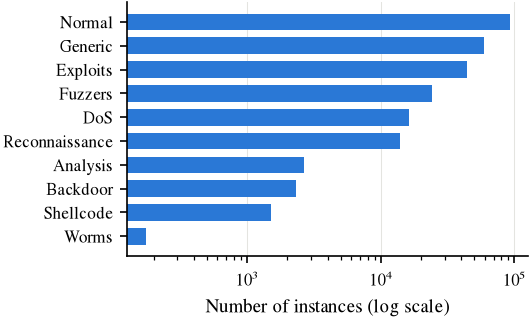

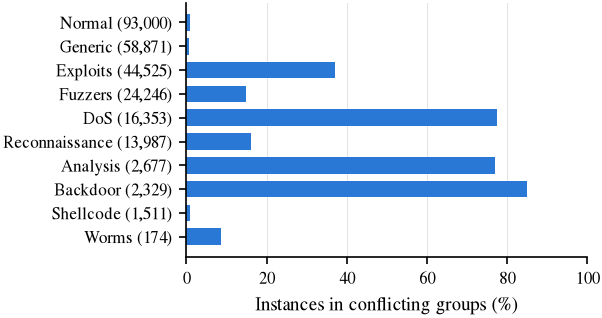

In [8]:
order = overlap_table.index[::-1]
names = [CLASS_NAMES[c] for c in order]
positions = np.arange(len(order))
# The overlap figure carries the class sizes in its labels, so the report
# needs only one figure for both properties.
count_names = [f"{CLASS_NAMES[c]} ({overlap_table.loc[c, 'count']:,})" for c in order]
for name, column, label in [
    ("class_distribution", "count", "Number of instances (log scale)"),
    ("class_overlap", "pct_in_conflicting_groups", "Instances in conflicting groups (%)"),
]:
    fig, ax = plt.subplots(figsize=(COLUMN_WIDTH, 2.2))
    ax.barh(positions, overlap_table.loc[order, column], height=0.7, color="#2a78d6")
    if column == "count":
        ax.set_xscale("log")
    else:
        ax.set_xlim(0, 100)
    ax.set_xlabel(label)
    ax.set_yticks(positions, count_names if column != "count" else names)
    ax.grid(axis="y", visible=False)
    save_figure(fig, name)
    plt.show()

## 2. Data transformations

Each model receives only the transformations its inductive bias requires.
Every transformation is fitted on training data only, inside each fold.

**Tree-based models (random forest and the revised classification tree).**
* `service` is missing for 54.8% of rows. Missingness is kept as an explicit
  category (`__MISSING__`) because missingness itself is informative; in
  UNSW-NB15 it denotes traffic without a recognised application protocol.
* Nominal features are **ordinally encoded** rather than one-hot encoded.
  A tree can isolate any single category of an ordinally coded feature with at
  most two threshold splits, so the arbitrary order does not restrict what the
  tree can represent. One-hot encoding turns `proto` alone into 133 sparse
  columns. For a random forest that is harmful: a split samples
  `max_features` columns at random, so most sampled columns become rarely
  useful indicator columns. RQ5 tests the choice empirically.
* Numeric features are passed through unchanged. Threshold splits are
  invariant to monotonic transformations, so scaling has no effect.
  Correlated features are retained: the forest benefits from alternative
  features when the strongest feature is not sampled at a split.

**kNN** keeps the Assignment 2 pipeline unchanged, so the comparison
reflects the Assignment 2 model: robust scaling, one-hot encoding, removal of
`sloss`, `dloss` and `ct_ftp_cmd`, and univariate feature selection.

In [9]:
def categorical_imputer():
    return SimpleImputer(strategy="constant", fill_value="__MISSING__")


def make_tree_preprocessor(encoding="ordinal"):
    if encoding == "ordinal":
        encoder = OrdinalEncoder(handle_unknown="use_encoded_value",
                                 unknown_value=-1, dtype=np.float32)
    else:
        encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False,
                                dtype=np.float32)
    return ColumnTransformer(
        [
            ("numeric", "passthrough", NUMERICAL),
            ("categorical", Pipeline([("missing", categorical_imputer()),
                                      ("encode", encoder)]), CATEGORICAL),
        ],
        verbose_feature_names_out=False,
    )


def encode(preprocessor, rows):
    return preprocessor.transform(X.iloc[rows]).astype(np.float32)


KNN_REDUNDANT = ["sloss", "dloss", "ct_ftp_cmd"]
KNN_NUMERICAL = [c for c in NUMERICAL if c not in KNN_REDUNDANT]


def make_knn_pipeline():
    preprocessor = ColumnTransformer([
        ("numeric", RobustScaler(), KNN_NUMERICAL),
        ("categorical", Pipeline([
            ("missing", categorical_imputer()),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), CATEGORICAL),
    ])
    return Pipeline([
        ("preprocess", preprocessor),
        ("select", SelectKBest(f_classif, k=60)),
        ("model", KNeighborsClassifier(n_jobs=N_JOBS)),
    ])

## 3. Empirical procedure

### 3.1 Performance measures

Let $TP_c$, $FP_c$ and $FN_c$ denote the true positives, false positives and
false negatives for class $c$, and let $C=10$ be the number of classes.

* Precision $P_c = TP_c/(TP_c+FP_c)$, recall $R_c = TP_c/(TP_c+FN_c)$, and
  $F1_c = 2P_cR_c/(P_c+R_c)$.
* **Macro-F1** $=\frac{1}{C}\sum_c F1_c$ is the primary measure. Every class
  counts equally, so the majority classes cannot mask poor rare-class
  performance. Macro-F1 is used for model selection on the evaluation set and
  for the final comparison on the test folds.
* Balanced accuracy $=\frac{1}{C}\sum_c R_c$, weighted F1 (class F1 weighted
  by support) and accuracy are reported as secondary measures.

### 3.2 Evaluation design

* **Outer loop:** stratified 5-fold cross-validation repeated twice
  (10 outer folds). Ten paired results are needed for the non-parametric
  tests: with five folds the smallest possible two-sided Wilcoxon p-value is
  0.0625, so no difference could ever be declared significant.
* **Inner split:** within each outer fold the development data are split
  80/20 (stratified) into a training set and an evaluation set. Every
  candidate configuration is fitted on the training set and scored on the
  evaluation set with macro-F1.
* The selected configuration is refitted on the full development data and
  scored once on the untouched outer test fold.
* All models use exactly the same outer folds and inner splits, so their
  results are paired.
* After cross-validation, a final forest is fitted on all 257,673 instances
  with the configuration selected most often. Its out-of-bag estimate is
  reported.

In [10]:
N_SPLITS, N_REPEATS = 5, 2
outer_cv = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS,
                                   random_state=RANDOM_STATE)
OUTER_SPLITS = list(outer_cv.split(X, y))
N_FOLDS = len(OUTER_SPLITS)


def inner_split(fold):
    dev_idx, _ = OUTER_SPLITS[fold]
    train_idx, eval_idx = train_test_split(
        dev_idx, test_size=0.20, stratify=y[dev_idx],
        random_state=RANDOM_STATE + fold,
    )
    return train_idx, eval_idx


def calculate_metrics(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
        "weighted_f1": f1_score(y_true, y_pred, average="weighted"),
    }


def per_class_f1(y_true, y_pred):
    scores = f1_score(y_true, y_pred, labels=CLASSES, average=None, zero_division=0)
    return {f"f1_{c}": s for c, s in zip(CLASSES, scores)}


def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro")


def cached(name, fold, compute):
    path = CACHE_DIR / f"{name}_fold{fold:02d}.pkl"
    if path.exists():
        with open(path, "rb") as handle:
            return pickle.load(handle)
    start = time.time()
    result = compute()
    result["seconds"] = time.time() - start
    with open(path, "wb") as handle:
        pickle.dump(result, handle)
    return result


split_sizes = []
for fold in range(N_FOLDS):
    train_idx, eval_idx = inner_split(fold)
    split_sizes.append({"fold": fold + 1, "training": len(train_idx),
                        "evaluation": len(eval_idx),
                        "test": len(OUTER_SPLITS[fold][1])})
pd.DataFrame(split_sizes).head(3)

,fold,training,evaluation,test
0,1,164910,41228,51535
1,2,164910,41228,51535
2,3,164910,41228,51535


### 3.3 Class weighting

Three class-weighting schemes are compared for the tree-based models. With
$N$ training instances and $N_c$ instances in class $c$:

* `none`: $w_c = 1$.
* `balanced`: $w_c = N/(C N_c)$. Every class contributes equal total weight
  (the scikit-learn `balanced` scheme).
* `sqrt`: $w_c = \sqrt{N/(C N_c)}$. A partial correction that halves the
  imbalance on a log scale. For *Worms* the weight is about 15 instead of
  about 150, so precision on the majority classes is sacrificed less.

The weights act differently in the two tree-based models (scikit-learn 1.9):

* **Classification tree:** the weights scale each instance's contribution to
  the impurity and to the leaf vote (cost-sensitive learning).
* **Random forest:** `fit` turns the class weights into bootstrap *sampling
  probabilities* (`_generate_sample_indices` in `sklearn/ensemble/_forest.py`).
  Each tree is grown on a class-reweighted bootstrap sample, so minority
  classes are oversampled and majority classes undersampled. `balanced` gives
  every class the same expected share of each bootstrap, which is the balanced
  random forest of Chen, Liaw and Breiman (2004). `sqrt` is a partial version.
  For the forest, RQ3 therefore tests resampling inside the ensemble rather
  than cost-sensitive splitting. The resampling happens inside each bootstrap,
  so it never touches the evaluation or test data.

In [11]:
def class_weight_dict(y_train, scheme):
    if scheme == "none":
        return None
    counts = np.bincount(y_train, minlength=N_CLASSES)
    weights = len(y_train) / (N_CLASSES * counts)
    if scheme == "sqrt":
        weights = np.sqrt(weights)
    return dict(zip(CLASSES.tolist(), weights))


pd.DataFrame({
    scheme: class_weight_dict(y, scheme) for scheme in ["sqrt", "balanced"]
}).rename(index=CLASS_NAMES).round(2)

,sqrt,balanced
Normal,0.53,0.28
Reconnaissance,1.36,1.84
Backdoor,3.33,11.06
DoS,1.26,1.58
Exploits,0.76,0.58
Analysis,3.10,9.63
Fuzzers,1.03,1.06
Worms,12.17,148.09
Shellcode,4.13,17.05
Generic,0.66,0.44


## 4. Models and tuning procedures

### 4.1 Majority baseline
The baseline predicts the most frequent training class for every instance.

In [12]:
def run_baseline_fold(fold):
    dev_idx, test_idx = OUTER_SPLITS[fold]
    model = DummyClassifier(strategy="most_frequent").fit(X.iloc[dev_idx], y[dev_idx])
    pred = model.predict(X.iloc[test_idx])
    return {"y_pred": pred.astype(np.int8), "metrics": calculate_metrics(y[test_idx], pred),
            "params": {}, "eval_macro_f1": np.nan}

### 4.2 Revised classification tree (Assignment 2 model)

The tree is revised in two ways relative to Assignment 2. Both changes make
the comparison with the forest cleaner.

1. It uses the same ordinal encoding as the forest. Any difference between
   the tree and the forest is then due to the ensemble mechanism alone.
2. The random sample of 30 configurations over six overlapping control
   parameters is replaced by a full grid over three parameters. Each grid
   axis matches a forest axis, so RQ2 and RQ3 can be answered for both
   models:
   * `criterion` ∈ {gini, entropy}: the two impurity measures in the
     background section.
   * `min_samples_leaf` ∈ {1, 3, 10, 30, 100}: a roughly logarithmic range
     from fully grown trees to strongly regularised trees. Leaf size is the
     only complexity control. Depth limits and cost-complexity pruning act on
     the same bias-variance trade-off; Assignment 2 almost always selected
     no pruning and near-unlimited depth.
   * `class_weight` ∈ {none, sqrt, balanced}.

The grid has 2 × 5 × 3 = 30 configurations, the same budget as Assignment 2.
The default tree is also fitted with one-hot encoding to answer RQ5.

In [13]:
TREE_GRID = {
    "criterion": ["gini", "entropy"],
    "min_samples_leaf": [1, 3, 10, 30, 100],
    "class_weight": WEIGHT_ORDER,
}


def make_tree(params, y_train, seed):
    return DecisionTreeClassifier(
        criterion=params["criterion"],
        min_samples_leaf=params["min_samples_leaf"],
        class_weight=class_weight_dict(y_train, params["class_weight"]),
        random_state=seed,
    )


def run_tree_fold(fold):
    dev_idx, test_idx = OUTER_SPLITS[fold]
    train_idx, eval_idx = inner_split(fold)
    seed = RANDOM_STATE + fold

    encoding_rows = []
    for encoding in ["ordinal", "onehot"]:
        pre = make_tree_preprocessor(encoding).fit(X.iloc[train_idx])
        X_train, X_eval = encode(pre, train_idx), encode(pre, eval_idx)
        start = time.time()
        tree = DecisionTreeClassifier(random_state=seed).fit(X_train, y[train_idx])
        encoding_rows.append({
            "encoding": encoding, "n_columns": X_train.shape[1],
            "fit_seconds": time.time() - start,
            "macro_f1": macro_f1(y[eval_idx], tree.predict(X_eval)),
        })

    pre = make_tree_preprocessor().fit(X.iloc[train_idx])
    X_train, X_eval = encode(pre, train_idx), encode(pre, eval_idx)
    rows = []
    for params in ParameterGrid(TREE_GRID):
        tree = make_tree(params, y[train_idx], seed).fit(X_train, y[train_idx])
        pred = tree.predict(X_eval)
        rows.append({**params, "macro_f1": macro_f1(y[eval_idx], pred),
                     **per_class_f1(y[eval_idx], pred),
                     "n_leaves": tree.get_n_leaves(), "depth": tree.get_depth()})
    tuning = pd.DataFrame(rows)
    best = tuning.loc[tuning["macro_f1"].idxmax()]
    best_params = {key: best[key] for key in TREE_GRID}
    best_params["min_samples_leaf"] = int(best_params["min_samples_leaf"])

    pre = make_tree_preprocessor().fit(X.iloc[dev_idx])
    final = make_tree(best_params, y[dev_idx], seed).fit(encode(pre, dev_idx), y[dev_idx])
    pred = final.predict(encode(pre, test_idx))
    return {
        "tuning": tuning, "encoding": pd.DataFrame(encoding_rows),
        "params": best_params, "eval_macro_f1": best["macro_f1"],
        "y_pred": pred.astype(np.int8), "metrics": calculate_metrics(y[test_idx], pred),
        "final_leaves": final.get_n_leaves(), "final_depth": final.get_depth(),
    }

### 4.3 Random forest

The forest uses bootstrap samples of the training data, Gini impurity and
soft voting: predicted class probabilities are averaged over the trees, as
scikit-learn does.

**Tuning design.** Each stage answers a question from the table above.

* **Stage 1 (RQ1, RQ3):** full factorial over
  `max_features` ∈ {0.05, 0.15, 0.3, 0.5, 0.75, 1.0} × `class_weight` ∈
  {none, sqrt, balanced}, with fully grown trees (`min_samples_leaf = 1`).
  With 42 features the fractions correspond to 2, 6, 12, 21, 31 and 42
  features per split. 6 ≈ √42 is the common default for classification, and
  1.0 reduces the forest to plain bagged trees.
* **Stage 2 (RQ2):** `min_samples_leaf` ∈ {3, 10, 30} at the best
  stage-1 combination. Leaf size has a smaller expected effect in a forest
  because averaging already reduces variance. A sequential stage therefore
  costs 3 instead of 54 extra fits.
* **Tuning ensembles use 100 trees.** Stage 1 also records the mean macro-F1
  of the individual trees (*strength*) and the mean pairwise disagreement
  between trees (*diversity*), to explain the `max_features` result.
* **Final ensembles use 300 trees (RQ4).** Adding trees to a forest does not
  cause overfitting, so the only cost of a larger forest is computation. The
  test-fold macro-F1 is tracked as trees are added. The curve is only
  reported, never used to choose a configuration.
* **RQ5:** the default forest (`max_features = sqrt`, 100 trees) is fitted
  with both encodings on the inner split.
* Permutation importance (macro-F1 decrease when one feature is shuffled) is
  computed on a stratified 10,000-instance subsample of the test fold for
  the five folds of the first repetition.

In [14]:
RF_TUNE_TREES = 20 if QUICK else 100
RF_FINAL_TREES = 40 if QUICK else 300
RF_MAX_FEATURES = [0.05, 0.15, 0.3, 0.5, 0.75, 1.0]
RF_LEAF_SIZES = [1, 3, 10, 30]
CURVE_POINTS = [t for t in [1, 2, 3, 5, 10, 15, 20, 30, 40, 50, 75, 100, 150, 200, 250, 300]
                if t <= RF_FINAL_TREES]


def make_forest(params, y_train, n_estimators, seed):
    return RandomForestClassifier(
        n_estimators=n_estimators,
        max_features=params["max_features"],
        min_samples_leaf=params["min_samples_leaf"],
        class_weight=class_weight_dict(y_train, params["class_weight"]),
        bootstrap=True,
        n_jobs=N_JOBS,
        random_state=seed,
    )


def member_statistics(forest, X_eval, y_eval):
    """Mean member macro-F1 (strength) and mean pairwise disagreement (diversity)."""
    votes = np.stack([tree.predict(X_eval) for tree in forest.estimators_]).astype(np.int64)
    n_trees = votes.shape[0]
    strength = np.mean([macro_f1(y_eval, forest.classes_[v]) for v in votes])
    counts = np.stack([(votes == k).sum(axis=0) for k in range(len(forest.classes_))], axis=1)
    agreeing_pairs = (counts * (counts - 1) / 2).sum(axis=1)
    disagreement = 1 - agreeing_pairs / (n_trees * (n_trees - 1) / 2)
    return strength, disagreement.mean()


def score_forest(params, X_train, y_train, X_eval, y_eval, seed, with_members):
    start = time.time()
    forest = make_forest(params, y_train, RF_TUNE_TREES, seed).fit(X_train, y_train)
    fit_seconds = time.time() - start
    pred = forest.predict(X_eval)
    row = {**params, "macro_f1": macro_f1(y_eval, pred), **per_class_f1(y_eval, pred),
           "fit_seconds": fit_seconds,
           "mean_leaves": np.mean([t.get_n_leaves() for t in forest.estimators_])}
    if with_members:
        row["tree_strength"], row["tree_disagreement"] = member_statistics(forest, X_eval, y_eval)
    return row


def run_forest_fold(fold):
    dev_idx, test_idx = OUTER_SPLITS[fold]
    train_idx, eval_idx = inner_split(fold)
    seed = RANDOM_STATE + fold
    y_train, y_eval, y_test = y[train_idx], y[eval_idx], y[test_idx]

    encoding_rows = []
    for encoding in ["ordinal", "onehot"]:
        pre = make_tree_preprocessor(encoding).fit(X.iloc[train_idx])
        X_tr, X_ev = encode(pre, train_idx), encode(pre, eval_idx)
        params = {"max_features": "sqrt", "min_samples_leaf": 1, "class_weight": "none"}
        row = score_forest(params, X_tr, y_train, X_ev, y_eval, seed, with_members=False)
        encoding_rows.append({"encoding": encoding, "n_columns": X_tr.shape[1],
                              "fit_seconds": row["fit_seconds"], "macro_f1": row["macro_f1"]})

    pre = make_tree_preprocessor().fit(X.iloc[train_idx])
    X_train, X_eval = encode(pre, train_idx), encode(pre, eval_idx)

    rows = []
    for max_features in RF_MAX_FEATURES:
        for scheme in WEIGHT_ORDER:
            params = {"max_features": max_features, "min_samples_leaf": 1,
                      "class_weight": scheme}
            rows.append({"stage": 1, **score_forest(
                params, X_train, y_train, X_eval, y_eval, seed, with_members=True)})
    stage1 = pd.DataFrame(rows)
    best1 = stage1.loc[stage1["macro_f1"].idxmax()]
    for leaf in RF_LEAF_SIZES[1:]:
        params = {"max_features": best1["max_features"], "min_samples_leaf": leaf,
                  "class_weight": best1["class_weight"]}
        rows.append({"stage": 2, **score_forest(
            params, X_train, y_train, X_eval, y_eval, seed, with_members=False)})
    tuning = pd.DataFrame(rows)
    best = tuning.loc[tuning["macro_f1"].idxmax()]
    best_params = {"max_features": float(best["max_features"]),
                   "min_samples_leaf": int(best["min_samples_leaf"]),
                   "class_weight": best["class_weight"]}

    pre = make_tree_preprocessor().fit(X.iloc[dev_idx])
    X_dev, X_test = encode(pre, dev_idx), encode(pre, test_idx)
    start = time.time()
    final = make_forest(best_params, y[dev_idx], RF_FINAL_TREES, seed).fit(X_dev, y[dev_idx])
    final_fit_seconds = time.time() - start

    probability_sum = np.zeros((len(test_idx), N_CLASSES))
    curve = {}
    for n_trees, tree in enumerate(final.estimators_, start=1):
        probability_sum += tree.predict_proba(X_test)
        if n_trees in CURVE_POINTS:
            curve[n_trees] = macro_f1(y_test, final.classes_[probability_sum.argmax(axis=1)])
    pred = final.classes_[probability_sum.argmax(axis=1)]

    result = {
        "tuning": tuning, "encoding": pd.DataFrame(encoding_rows),
        "params": best_params, "eval_macro_f1": best["macro_f1"],
        "y_pred": pred.astype(np.int8), "metrics": calculate_metrics(y_test, pred),
        "tree_curve": curve, "final_fit_seconds": final_fit_seconds,
        "feature_names": list(pre.get_feature_names_out()),
        "mdi_importance": final.feature_importances_,
    }

    if fold < N_SPLITS:
        sample = np.arange(len(test_idx))
        if len(test_idx) > 20_000:
            sample, _ = train_test_split(sample, train_size=10_000, stratify=y_test,
                                         random_state=seed)
        importance = permutation_importance(
            final, X_test[sample], y_test[sample], scoring="f1_macro",
            n_repeats=3, random_state=seed, n_jobs=1)
        result["permutation_importance"] = importance.importances_mean
    return result

### 4.4 k-nearest neighbours (Assignment 2 model, unchanged)

The kNN model uses the Assignment 2 pipeline and the same 15 candidate
configurations that Assignment 2 sampled at random. Because the candidate
pool is unchanged, kNN is evaluated exactly as it was in Assignment 2, apart
from the new outer folds.

In [15]:
KNN_CANDIDATES = [
    {"select__k": k, "model__weights": w, "model__p": p, "model__n_neighbors": n}
    for k, w, p, n in [
        ("all", "uniform", 2, 31), ("all", "distance", 2, 11), (60, "uniform", 1, 15),
        (80, "uniform", 2, 3), (80, "distance", 2, 11), (60, "distance", 2, 5),
        (60, "uniform", 2, 7), (80, "uniform", 2, 21), (40, "distance", 1, 15),
        ("all", "uniform", 2, 15), (40, "distance", 1, 11), (120, "distance", 2, 3),
        (40, "distance", 1, 7), (60, "uniform", 2, 31), (40, "uniform", 1, 5),
    ]
]


def run_knn_fold(fold):
    dev_idx, test_idx = OUTER_SPLITS[fold]
    train_idx, eval_idx = inner_split(fold)
    rows = []
    for number, params in enumerate(KNN_CANDIDATES, start=1):
        if QUICK and isinstance(params["select__k"], int):
            params = {**params, "select__k": min(params["select__k"], 40)}
        model = make_knn_pipeline().set_params(**params).fit(X.iloc[train_idx], y[train_idx])
        pred = model.predict(X.iloc[eval_idx])
        rows.append({"candidate": number, **params, "macro_f1": macro_f1(y[eval_idx], pred),
                     **per_class_f1(y[eval_idx], pred)})
    tuning = pd.DataFrame(rows)
    best = tuning.loc[tuning["macro_f1"].idxmax()]
    best_params = KNN_CANDIDATES[int(best["candidate"]) - 1]
    if QUICK and isinstance(best_params["select__k"], int):
        best_params = {**best_params, "select__k": min(best_params["select__k"], 40)}
    final = make_knn_pipeline().set_params(**best_params).fit(X.iloc[dev_idx], y[dev_idx])
    pred = final.predict(X.iloc[test_idx])
    return {"tuning": tuning, "params": best_params, "eval_macro_f1": best["macro_f1"],
            "y_pred": pred.astype(np.int8), "metrics": calculate_metrics(y[test_idx], pred)}

### 4.5 Class-weighted k-nearest neighbours (revised Assignment 2 model)

The Assignment 2 kNN has no mechanism to counter class imbalance: every
neighbour votes with the same weight regardless of the frequency of its
class. The revised kNN multiplies the vote of each neighbour by the weight
$w_c$ of the neighbour's class, using the same three schemes as the trees.
With `balanced` weights the vote for class $c$ is proportional to
$k_c/N_c$, the share of class $c$ among the neighbours divided by the
frequency of class $c$. That ratio estimates the class-conditional density
rather than the posterior, so the decision ignores the class priors. The
`sqrt` scheme removes half of the prior on a log scale.

The neighbour search and the vote are implemented directly in NumPy rather
than with scikit-learn's classifier:

* Squared Euclidean distances are computed in blocks of 500 queries as
  $\|\mathbf{a}\|^2 + \|\mathbf{b}\|^2 - 2\mathbf{a}^\top\mathbf{b}$ in
  double precision, and the 31 nearest reference instances are kept per query.
* One search with the largest neighbourhood serves every candidate value of
  $k \le 31$, every vote type and every class-weighting scheme. A full grid of
  8 × 2 × 3 = 48 configurations therefore costs one neighbour search per fold.
* With distance weighting, a neighbour at zero distance (an exact duplicate)
  receives all of the vote, as in scikit-learn. 46.5% of the instances have
  an exact duplicate, so this case is frequent.

The pre-processing is the Assignment 2 pipeline. The number of selected
features (60) and the Euclidean distance are fixed. The Assignment 2 tuning
above selected both in eight of the ten folds, so the revised model spends
its tuning budget on the vote instead.

In [16]:
KNN_K_VALUES = [1, 3, 5, 7, 11, 15, 21, 31]
KNN_VOTES = ["uniform", "distance"]


def knn_feature_pipeline():
    return Pipeline(make_knn_pipeline().steps[:-1])


def nearest_neighbours(reference, queries, k, block=500):
    """Distances and indices of the k nearest reference rows, nearest first."""
    reference_sq = np.einsum("ij,ij->i", reference, reference)
    distances = np.empty((len(queries), k))
    indices = np.empty((len(queries), k), dtype=np.int64)
    for start in range(0, len(queries), block):
        block_q = queries[start:start + block]
        squared = (reference_sq[None, :] - 2.0 * block_q @ reference.T
                   + np.einsum("ij,ij->i", block_q, block_q)[:, None])
        np.maximum(squared, 0.0, out=squared)
        nearest = np.argpartition(squared, k - 1, axis=1)[:, :k]
        nearest_sq = np.take_along_axis(squared, nearest, axis=1)
        order = np.argsort(nearest_sq, axis=1, kind="stable")
        indices[start:start + block] = np.take_along_axis(nearest, order, axis=1)
        distances[start:start + block] = np.sqrt(np.take_along_axis(nearest_sq, order, axis=1))
    return distances, indices


def class_weight_array(y_train, scheme):
    weights = class_weight_dict(y_train, scheme)
    return np.ones(N_CLASSES) if weights is None else np.array([weights[c] for c in CLASSES])


def weighted_vote(distances, neighbour_labels, k, vote, class_weights):
    distances, labels = distances[:, :k], neighbour_labels[:, :k]
    if vote == "uniform":
        weights = np.ones_like(distances)
    else:
        exact = distances < 1e-9
        weights = np.where(exact.any(axis=1, keepdims=True), exact.astype(float),
                           1.0 / np.maximum(distances, 1e-9))
    weights = weights * class_weights[labels]
    scores = np.stack([(weights * (labels == c)).sum(axis=1) for c in CLASSES], axis=1)
    return CLASSES[scores.argmax(axis=1)]


def run_weighted_knn_fold(fold):
    dev_idx, test_idx = OUTER_SPLITS[fold]
    train_idx, eval_idx = inner_split(fold)

    pre = knn_feature_pipeline().fit(X.iloc[train_idx], y[train_idx])
    reference = pre.transform(X.iloc[train_idx]).astype(np.float64)
    queries = pre.transform(X.iloc[eval_idx]).astype(np.float64)
    distances, indices = nearest_neighbours(reference, queries, max(KNN_K_VALUES))
    neighbour_labels = y[train_idx][indices]

    rows = []
    for k in KNN_K_VALUES:
        for vote in KNN_VOTES:
            for scheme in WEIGHT_ORDER:
                pred = weighted_vote(distances, neighbour_labels, k, vote,
                                     class_weight_array(y[train_idx], scheme))
                rows.append({"n_neighbors": k, "vote": vote, "class_weight": scheme,
                             "macro_f1": macro_f1(y[eval_idx], pred),
                             **per_class_f1(y[eval_idx], pred)})
    tuning = pd.DataFrame(rows)
    best = tuning.loc[tuning["macro_f1"].idxmax()]
    best_params = {"n_neighbors": int(best["n_neighbors"]), "vote": best["vote"],
                   "class_weight": best["class_weight"]}

    pre = knn_feature_pipeline().fit(X.iloc[dev_idx], y[dev_idx])
    reference = pre.transform(X.iloc[dev_idx]).astype(np.float64)
    queries = pre.transform(X.iloc[test_idx]).astype(np.float64)
    distances, indices = nearest_neighbours(reference, queries, best_params["n_neighbors"])
    pred = weighted_vote(distances, y[dev_idx][indices], best_params["n_neighbors"],
                         best_params["vote"], class_weight_array(y[dev_idx], best_params["class_weight"]))
    return {"tuning": tuning, "params": best_params, "eval_macro_f1": best["macro_f1"],
            "y_pred": pred.astype(np.int8), "metrics": calculate_metrics(y[test_idx], pred)}

## 5. Run the experiment

The experiment runs model by model so that completed models are cached
early. Expect roughly 30 minutes for the tree, 3 hours for the forest and
2 hours for kNN on 8 cores.

In [17]:
RUNNERS = {
    "Majority baseline": ("baseline", run_baseline_fold),
    "Classification tree": ("tree", run_tree_fold),
    "Random forest": ("forest", run_forest_fold),
    "k-nearest neighbours": ("knn", run_knn_fold),
    "Class-weighted k-nearest neighbours": ("knn_weighted", run_weighted_knn_fold),
}

fold_outputs = {}
for model_name, (key, runner) in RUNNERS.items():
    fold_outputs[model_name] = []
    for fold in range(N_FOLDS):
        output = cached(key, fold, lambda: runner(fold))
        fold_outputs[model_name].append(output)
        print(f"{model_name:36s} fold {fold + 1:2d}: test macro-F1 "
              f"{output['metrics']['macro_f1']:.4f} ({output['seconds']:.0f} s) "
              f"params={output['params']}", flush=True)

Majority baseline                    fold  1: test macro-F1 0.0530 (0 s) params={}


Majority baseline                    fold  2: test macro-F1 0.0530 (0 s) params={}


Majority baseline                    fold  3: test macro-F1 0.0530 (0 s) params={}


Majority baseline                    fold  4: test macro-F1 0.0530 (0 s) params={}


Majority baseline                    fold  5: test macro-F1 0.0530 (0 s) params={}


...

Class-weighted k-nearest neighbours  fold  6: test macro-F1 0.5166 (379 s) params={'n_neighbors': 5, 'vote': 'distance', 'class_weight': 'none'}


Class-weighted k-nearest neighbours  fold  7: test macro-F1 0.5111 (365 s) params={'n_neighbors': 7, 'vote': 'distance', 'class_weight': 'none'}


Class-weighted k-nearest neighbours  fold  8: test macro-F1 0.5065 (357 s) params={'n_neighbors': 31, 'vote': 'distance', 'class_weight': 'sqrt'}


Class-weighted k-nearest neighbours  fold  9: test macro-F1 0.5124 (331 s) params={'n_neighbors': 5, 'vote': 'distance', 'class_weight': 'none'}


Class-weighted k-nearest neighbours  fold 10: test macro-F1 0.5228 (346 s) params={'n_neighbors': 5, 'vote': 'distance', 'class_weight': 'none'}


## 6. Results

### 6.1 Overall performance across the ten outer test folds

In [18]:
METRICS = ["accuracy", "balanced_accuracy", "macro_f1", "weighted_f1"]
ALL_MODELS = MODEL_ORDER + ["Majority baseline"]

fold_results = pd.DataFrame([
    {"model": model, "fold": fold + 1, "repeat": fold // N_SPLITS + 1,
     "eval_macro_f1": output["eval_macro_f1"], **output["metrics"]}
    for model, outputs in fold_outputs.items() for fold, output in enumerate(outputs)
])
fold_results.to_csv(TABLE_DIR / "outer_fold_results.csv", index=False)

summary = fold_results.groupby("model")[METRICS].agg(["mean", "std"]).reindex(ALL_MODELS)
summary.to_csv(TABLE_DIR / "performance_summary.csv")
summary.round(4)

accuracy         balanced_accuracy         macro_f1         weighted_f1        
                                        mean     std              mean     std     mean     std        mean     std
model                                                                                                              
Random forest                         0.8233  0.0021            0.6471  0.0148   0.6287  0.0097      0.8298  0.0018
Classification tree                   0.8008  0.0028            0.6113  0.0167   0.5930  0.0090      0.8079  0.0021
Class-weighted k-nearest neighbours   0.7901  0.0098            0.5156  0.0340   0.5147  0.0108      0.7893  0.0035
k-nearest neighbours                  0.7935  0.0028            0.5013  0.0089   0.5195  0.0079      0.7903  0.0016
Majority baseline                     0.3609  0.0000            0.1000  0.0000   0.0530  0.0000      0.1914  0.0000

### 6.2 Statistical comparison

Following the course notes, a Friedman test checks whether the three models
differ in macro-F1 over the ten paired folds. Pairwise Wilcoxon signed-rank
tests with the Holm correction then locate the differences. The folds of
repeated cross-validation share training data, so the fold results are not
fully independent. The p-values should therefore be read as approximate.
The Nadeau–Bengio corrected resampled t-test, which accounts for the
overlap, is also reported for each pair.

In [19]:
def holm(p_values):
    p_values = np.asarray(p_values)
    order = np.argsort(p_values)
    adjusted = np.empty_like(p_values)
    running = 0.0
    for rank, index in enumerate(order):
        running = max(running, (len(p_values) - rank) * p_values[index])
        adjusted[index] = min(1.0, running)
    return adjusted


def corrected_t_test(differences, test_fraction):
    """Nadeau and Bengio (2003) corrected resampled t-test."""
    n = len(differences)
    variance = np.var(differences, ddof=1)
    statistic = np.mean(differences) / np.sqrt((1 / n + test_fraction / (1 - test_fraction)) * variance)
    return statistic, 2 * stats.t.sf(abs(statistic), df=n - 1)


def compare_models(metric):
    wide = fold_results.pivot(index="fold", columns="model", values=metric)[MODEL_ORDER]
    friedman = stats.friedmanchisquare(*[wide[m] for m in MODEL_ORDER])
    rows = []
    pairs = [(a, b) for i, a in enumerate(MODEL_ORDER) for b in MODEL_ORDER[i + 1:]]
    for a, b in pairs:
        difference = wide[a] - wide[b]
        wilcoxon = stats.wilcoxon(wide[a], wide[b])
        _, corrected_p = corrected_t_test(difference.to_numpy(), 1 / N_SPLITS)
        rows.append({"model_a": a, "model_b": b, "mean_difference": difference.mean(),
                     "wins_a": int((difference > 0).sum()), "wins_b": int((difference < 0).sum()),
                     "wilcoxon_p": wilcoxon.pvalue, "corrected_t_p": corrected_p})
    table = pd.DataFrame(rows)
    table["wilcoxon_p_holm"] = holm(table["wilcoxon_p"])
    table["corrected_t_p_holm"] = holm(table["corrected_t_p"])
    ranks = wide.rank(axis=1, ascending=False).mean().rename("mean_rank")
    return friedman, table, ranks


statistics_rows = []
for metric in ["macro_f1", "balanced_accuracy", "accuracy"]:
    friedman, pairwise, ranks = compare_models(metric)
    print(f"{metric}: Friedman chi2 = {friedman.statistic:.2f}, p = {friedman.pvalue:.2e}; "
          f"mean ranks {ranks.round(2).to_dict()}")
    statistics_rows.append(pairwise.assign(metric=metric))
statistical_tests = pd.concat(statistics_rows, ignore_index=True)
statistical_tests.to_csv(TABLE_DIR / "statistical_tests.csv", index=False)
statistical_tests.round(4)

macro_f1: Friedman chi2 = 28.08, p = 3.49e-06; mean ranks {'Random forest': 1.0, 'Classification tree': 2.0, 'Class-weighted k-nearest neighbours': 3.8, 'k-nearest neighbours': 3.2}


balanced_accuracy: Friedman chi2 = 27.00, p = 5.89e-06; mean ranks {'Random forest': 1.0, 'Classification tree': 2.0, 'Class-weighted k-nearest neighbours': 3.5, 'k-nearest neighbours': 3.5}


accuracy: Friedman chi2 = 27.12, p = 5.56e-06; mean ranks {'Random forest': 1.0, 'Classification tree': 2.0, 'Class-weighted k-nearest neighbours': 3.4, 'k-nearest neighbours': 3.6}


,model_a,model_b,mean_difference,wins_a,wins_b,wilcoxon_p,corrected_t_p,wilcoxon_p_holm,corrected_t_p_holm,metric
0,Random forest,Classification tree,0.0357,10,0,0.0020,0.0001,0.0117,0.0003,macro_f1
1,Random forest,Class-weighted k-nearest neighbours,0.1140,10,0,0.0020,0.0000,0.0117,0.0000,macro_f1
2,Random forest,k-nearest neighbours,0.1093,10,0,0.0020,0.0000,0.0117,0.0000,macro_f1
3,Classification tree,Class-weighted k-nearest neighbours,0.0782,10,0,0.0020,0.0000,0.0117,0.0000,macro_f1
4,Classification tree,k-nearest neighbours,0.0735,10,0,0.0020,0.0000,0.0117,0.0000,macro_f1
5,Class-weighted k-nearest neighbours,k-nearest neighbours,-0.0047,2,8,0.0273,0.3289,0.0273,0.3289,macro_f1
6,Random forest,Classification tree,0.0358,10,0,0.0020,0.0159,0.0117,0.0318,balanced_accuracy
7,Random forest,Class-weighted k-nearest neighbours,0.1315,10,0,0.0020,0.0007,0.0117,0.0028,balanced_accuracy
8,Random forest,k-nearest neighbours,0.1458,10,0,0.0020,0.0000,0.0117,0.0000,balanced_accuracy
9,Classification tree,Class-weighted k-nearest neighbours,0.0957,10,0,0.0020,0.0026,0.0117,0.0077,balanced_accuracy


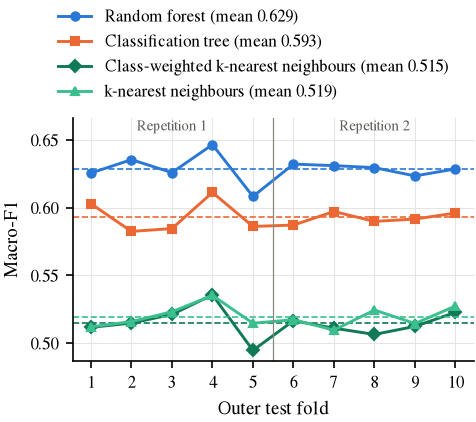

In [20]:
fig, ax = plt.subplots(figsize=(COLUMN_WIDTH, 2.1))
folds = np.arange(1, N_FOLDS + 1)
for model in MODEL_ORDER:
    values = fold_results.query("model == @model").sort_values("fold")["macro_f1"]
    ax.plot(folds, values, marker=MODEL_MARKERS[model], color=MODEL_COLOURS[model],
            label=f"{model} (mean {values.mean():.3f})")
    ax.axhline(values.mean(), color=MODEL_COLOURS[model], linestyle="--", linewidth=0.8)
ax.axvline(N_SPLITS + 0.5, color="#8a8a85", linewidth=0.6)
top = ax.get_ylim()[1]
ax.set_ylim(top=top + 0.012)
ax.text(N_SPLITS / 2 + 0.5, top + 0.011, "Repetition 1", ha="center", va="top",
        fontsize=7, color="#5f5f5a")
ax.text(N_SPLITS * 1.5 + 0.5, top + 0.011, "Repetition 2", ha="center", va="top",
        fontsize=7, color="#5f5f5a")
ax.set_xticks(folds)
ax.set_xlabel("Outer test fold")
ax.set_ylabel("Macro-F1")
ax.legend(loc="lower center", bbox_to_anchor=(0.45, 1.01), ncol=1)
save_figure(fig, "macro_f1_by_fold")
plt.show()

### 6.3 Per-class performance

Per-class precision, recall and F1 are computed on each test fold and
averaged over the ten folds. The last two columns give the number of folds on
which the forest's F1 exceeds the tree's, and the per-class F1 bound.

In [21]:
def per_class_frame(model):
    rows = []
    for fold, output in enumerate(fold_outputs[model]):
        test_idx = OUTER_SPLITS[fold][1]
        p, r, f, _ = precision_recall_fscore_support(
            y[test_idx], output["y_pred"], labels=CLASSES, zero_division=0)
        for c in CLASSES:
            rows.append({"model": model, "fold": fold + 1, "class": CLASS_NAMES[c],
                         "precision": p[c], "recall": r[c], "f1": f[c]})
    return pd.DataFrame(rows)


per_class = pd.concat([per_class_frame(m) for m in MODEL_ORDER], ignore_index=True)
class_order = [CLASS_NAMES[c] for c in overlap_table.index]
per_class_summary = (
    per_class.groupby(["class", "model"])[["precision", "recall", "f1"]].mean()
    .unstack("model").reindex(class_order)
)
wide_f1 = per_class.pivot_table(index=["class", "fold"], columns="model", values="f1")
per_class_summary[("forest_wins_vs_tree", "")] = (
    (wide_f1["Random forest"] > wide_f1["Classification tree"]).groupby("class").sum()
)
per_class_summary[("f1_bound", "")] = overlap_table.set_index("class")["f1_bound"]
per_class_summary.to_csv(TABLE_DIR / "per_class_summary.csv")
per_class_summary.round(3)

precision                                                                                     recall  \
model          Class-weighted k-nearest neighbours Classification tree Random forest k-nearest neighbours Class-weighted k-nearest neighbours   
class                                                                                                                                           
Normal                                       0.900               0.921         0.943                0.889                               0.905   
Generic                                      0.996               0.992         0.997                0.996                               0.976   
Exploits                                     0.668               0.735         0.753                0.661                               0.678   
Fuzzers                                      0.614               0.644         0.694                0.629                               0.558   
DoS                                          0.337               0.333         0.352                0.345                               0.412   
Reconnaissance                               0.708               0.888         0.902                0.713                               0.736   
Analysis                                     0.455               0.215         0.263                0.561                               0.124   
Backdoor                                     0.099               0.116         0.132                0.160                               0.049   
Shellcode                                    0.468               0.568         0.628                0.510                               0.474   
Worms                                        0.340               0.507         0.618                0.457                               0.244   

                                                                                                       f1                                    \
model          Classification tree Random forest k-nearest neighbours Class-weighted k-nearest neighbours Classification tree Random forest   
class                                                                                                                                         
Normal                       0.906         0.921                0.920                               0.902               0.914         0.932   
Generic                      0.982         0.982                0.977                               0.986               0.987         0.990   
Exploits                     0.611         0.653                0.684                               0.671               0.667         0.699   
Fuzzers                      0.605         0.693                0.527                               0.583               0.624         0.693   
DoS                          0.601         0.600                0.426                               0.369               0.429         0.444   
Reconnaissance               0.764         0.785                0.722                               0.721               0.821         0.839   
Analysis                     0.135         0.128                0.117                               0.184               0.165         0.172   
Backdoor                     0.137         0.143                0.049                               0.062               0.126         0.137   
Shellcode                    0.697         0.805                0.425                               0.451               0.625         0.705   
Worms                        0.675         0.762                0.166                               0.219               0.573         0.677   

                                    forest_wins_vs_tree f1_bound  
model          k-nearest neighbours                               
class                                                             
Normal                        0.904                  10    0.996  
Generic                    

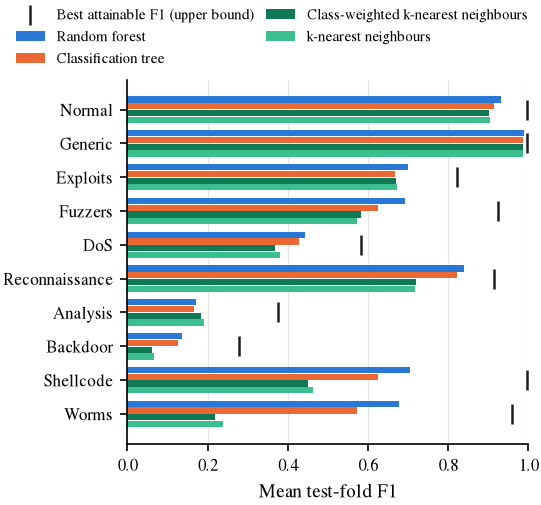

In [22]:
fig, ax = plt.subplots(figsize=(COLUMN_WIDTH, 3.15))
positions = np.arange(len(class_order))[::-1]
bar_height = 0.2
for offset, model in zip([1.5 * bar_height, 0.5 * bar_height, -0.5 * bar_height, -1.5 * bar_height],
                         MODEL_ORDER):
    values = per_class_summary[("f1", model)].to_numpy()
    ax.barh(positions + offset, values, height=bar_height * 0.92,
            color=MODEL_COLOURS[model], label=model)
ceiling = overlap_table["f1_bound"].to_numpy()
ax.scatter(ceiling, positions, marker="|", s=90, color="#1f1f1d", linewidths=1.2,
           label="Best attainable F1 (upper bound)", zorder=3)
ax.set_yticks(positions, class_order)
ax.set_xlim(0, 1.0)
ax.set_xlabel("Mean test-fold F1")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower center", bbox_to_anchor=(0.36, 1.0), ncol=2, columnspacing=0.8,
          fontsize=7)
save_figure(fig, "per_class_f1")
plt.show()

Confusion matrix of the random forest, pooled over the five test folds of
the first repetition (each instance appears exactly once) and normalised by
row, so each row shows how the instances of one true class were predicted.

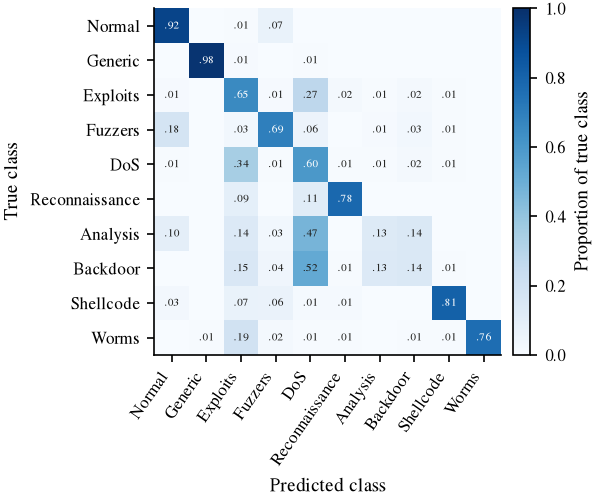

In [23]:
def pooled_confusion(model, repeat=1):
    folds = range((repeat - 1) * N_SPLITS, repeat * N_SPLITS)
    y_true = np.concatenate([y[OUTER_SPLITS[f][1]] for f in folds])
    y_pred = np.concatenate([fold_outputs[model][f]["y_pred"] for f in folds])
    return confusion_matrix(y_true, y_pred, labels=CLASSES, normalize="true")


order = overlap_table.index.to_numpy()
fig, ax = plt.subplots(figsize=(COLUMN_WIDTH, 3.0))
matrix = pooled_confusion("Random forest")[np.ix_(order, order)]
image = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=1)
labels = [CLASS_NAMES[c] for c in order]
ax.set_xticks(range(N_CLASSES), labels, rotation=55, ha="right")
ax.set_yticks(range(N_CLASSES), labels)
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
ax.grid(False)
for i in range(N_CLASSES):
    for j in range(N_CLASSES):
        if matrix[i, j] >= 0.005:
            ax.text(j, i, f"{matrix[i, j]:.2f}".lstrip("0"), ha="center", va="center",
                    fontsize=5.5, color="white" if matrix[i, j] > 0.55 else "#1f1f1d")
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.03, label="Proportion of true class")
save_figure(fig, "forest_confusion_matrix")
plt.show()
pd.DataFrame(matrix, index=labels, columns=labels).round(3).to_csv(
    TABLE_DIR / "forest_confusion_matrix.csv")

### 6.4 Selected configurations and how well tuning generalises

Each model selects its configuration on the evaluation set. The gap between
the evaluation-set score of the selected configuration and its test-fold
score shows whether tuning overfits the evaluation set.

In [24]:
selected = pd.DataFrame([
    {"model": model, "fold": fold + 1, **output["params"]}
    for model in MODEL_ORDER for fold, output in enumerate(fold_outputs[model])
])
selected.to_csv(TABLE_DIR / "selected_configurations.csv", index=False)

generalisation = fold_results.query("model in @MODEL_ORDER").assign(
    gap=lambda d: d["eval_macro_f1"] - d["macro_f1"])
generalisation_summary = generalisation.groupby("model")[["eval_macro_f1", "macro_f1", "gap"]].agg(
    ["mean", "std"]).reindex(MODEL_ORDER)
generalisation_summary.to_csv(TABLE_DIR / "tuning_generalisation.csv")
display(generalisation_summary.round(4))

for model in MODEL_ORDER:
    columns = [c for c in selected.columns if c not in ("model", "fold")]
    counts = (selected.query("model == @model")[columns].dropna(axis=1)
              .astype(str).value_counts().rename("folds"))
    print(model)
    print(counts.to_string(), "\n")

eval_macro_f1         macro_f1             gap        
                                             mean     std     mean     std    mean     std
model                                                                                     
Random forest                              0.6261  0.0085   0.6287  0.0097 -0.0026  0.0145
Classification tree                        0.5940  0.0074   0.5930  0.0090  0.0010  0.0109
Class-weighted k-nearest neighbours        0.5125  0.0077   0.5147  0.0108 -0.0022  0.0086
k-nearest neighbours                       0.5130  0.0066   0.5195  0.0079 -0.0064  0.0101

Random forest
max_features  min_samples_leaf  class_weight
0.75          1.0               sqrt            4
0.5           1.0               sqrt            4
              3.0               sqrt            2 

Classification tree
min_samples_leaf  class_weight  criterion
3.0               sqrt          gini         5
1.0               sqrt          entropy      3
3.0               sqrt          entropy      2 

Class-weighted k-nearest neighbours
class_weight  n_neighbors  vote    
none          5.0          distance    6
              7.0          distance    2
sqrt          21.0         distance    1
              31.0         distance    1 

k-nearest neighbours
select__k  model__weights  model__p  model__n_neighbors
60         distance        2.0       5.0                   8
all        distance        2.0       11.0                  2 



### 6.5 RQ1: features per split, strength and diversity

The mean evaluation-set macro-F1 of each stage-1 configuration is averaged
over the ten folds. Error bars show one standard deviation over folds.

In [25]:
forest_tuning = pd.concat(
    [output["tuning"].assign(fold=fold + 1) for fold, output in enumerate(fold_outputs["Random forest"])],
    ignore_index=True)
forest_tuning.to_csv(TABLE_DIR / "forest_tuning_all_folds.csv", index=False)
stage1 = forest_tuning.query("stage == 1")

rq1 = stage1.groupby(["class_weight", "max_features"])[
    ["macro_f1", "tree_strength", "tree_disagreement", "fit_seconds"]].agg(["mean", "std"])
rq1.to_csv(TABLE_DIR / "rq1_max_features.csv")
display(rq1.round(4))

# Paired test: best random-subspace setting versus plain bagging (max_features = 1.0).
no_weight = stage1.query("class_weight == 'none'").pivot(
    index="fold", columns="max_features", values="macro_f1")
best_fraction = no_weight.drop(columns=1.0).mean().idxmax()
test = stats.wilcoxon(no_weight[best_fraction], no_weight[1.0])
print(f"Best random-subspace max_features (no weighting) = {best_fraction}; "
      f"mean gain over bagging = {(no_weight[best_fraction] - no_weight[1.0]).mean():.4f}, "
      f"wins {(no_weight[best_fraction] > no_weight[1.0]).sum()}/{N_FOLDS}, Wilcoxon p = {test.pvalue:.4f}")

macro_f1         tree_strength         tree_disagreement         fit_seconds         
                              mean     std          mean     std              mean     std        mean      std
class_weight max_features                                                                                      
balanced     0.05           0.5500  0.0086        0.4872  0.0032            0.1959  0.0014      9.6249   3.1768
             0.15           0.5763  0.0073        0.5214  0.0044            0.1819  0.0013     15.2317   5.3994
             0.30           0.5844  0.0082        0.5365  0.0053            0.1754  0.0012     23.0102   6.5737
             0.50           0.5867  0.0077        0.5433  0.0061            0.1719  0.0012     37.8987  11.7520
             0.75           0.5855  0.0083        0.5454  0.0064            0.1697  0.0013     54.5403  14.2374
             1.00           0.5764  0.0083        0.5464  0.0067            0.1656  0.0013     72.7201  22.6181
none         0.05           0.5415  0.0066        0.4928  0.0029            0.1927  0.0009      9.7922   3.0798
             0.15           0.5726  0.0110        0.5203  0.0044            0.1798  0.0011     17.8709   5.3698
             0.30           0.5917  0.0106        0.5370  0.0050            0.1739  0.0009     30.4888   8.0864
             0.50           0.6011  0.0090        0.5456  0.0057            0.1709  0.0011     50.6302  16.0848
             0.75           0.6052  0.0113        0.5498  0.0064            0.1691  0.0011     76.1106  23.0513
             1.00           0.6030  0.0087        0.5521  0.0063            0.1672  0.0010    102.9696  31.9233
sqrt         0.05           0.5684  0.0071        0.5036  0.0032            0.2004  0.0011     11.3340   3.4189
             0.15           0.6064  0.0097        0.5353  0.0044            0.1870  0.0007     18.9475   6.5168
             0.30           0.6185  0.0079        0.5550  0.0061            0.1806  0.0007     32.0938  10.5310
             0.50           0.6248  0.0091        0.5652  0.0059            0.1771  0.0008     51.9444  16.2941
             0.75           0.6232  0.0101        0.5685  0.0065            0.1750  0.0009     74.0518  20.8355
             1.00           0.6155  0.0081        0.5689  0.0065            0.1716  0.0008     99.1823  29.0503

Best random-subspace max_features (no weighting) = 0.75; mean gain over bagging = 0.0022, wins 7/10, Wilcoxon p = 0.1602


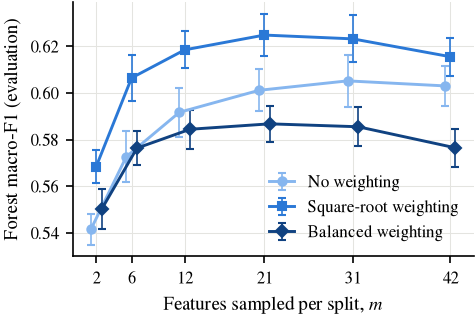

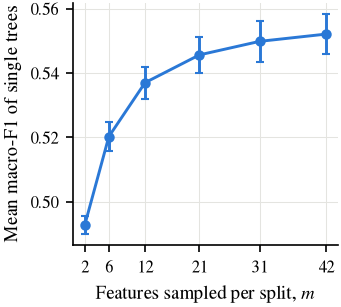

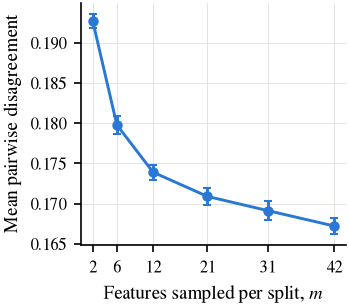

In [26]:
n_features = len(feature_columns)
PANEL_WIDTH = FULL_WIDTH / 3 - 0.05

fig, ax = plt.subplots(figsize=(COLUMN_WIDTH, 2.2))
for dodge, scheme in zip([-0.6, 0, 0.6], WEIGHT_ORDER):
    part = rq1.loc[scheme]
    features_per_split = [max(1, int(f * n_features)) for f in part.index]
    ax.errorbar(np.array(features_per_split) + dodge, part[("macro_f1", "mean")],
                yerr=part[("macro_f1", "std")], marker=WEIGHT_MARKERS[scheme],
                color=WEIGHT_COLOURS[scheme], label=WEIGHT_LABELS[scheme],
                capsize=2, elinewidth=0.8)
ax.set_xticks(features_per_split)
ax.set_xlabel("Features sampled per split, $m$")
ax.set_ylabel("Forest macro-F1 (evaluation)")
ax.legend(loc="lower right", handlelength=1.5)
save_figure(fig, "rq1_forest")
plt.show()

part = rq1.loc["none"]
for name, column, label in [("rq1_strength", "tree_strength", "Mean macro-F1 of single trees"),
                            ("rq1_diversity", "tree_disagreement", "Mean pairwise disagreement")]:
    fig, ax = plt.subplots(figsize=(PANEL_WIDTH, 2.1))
    ax.errorbar(features_per_split, part[(column, "mean")], yerr=part[(column, "std")],
                marker="o", color="#2a78d6", capsize=2)
    ax.set_xticks(features_per_split)
    ax.set_xlabel("Features sampled per split, $m$")
    ax.set_ylabel(label)
    save_figure(fig, name)
    plt.show()

### 6.6 RQ2: leaf size in a forest versus a single tree

For the forest, each fold's curve uses the fold's best stage-1 combination
of `max_features` and `class_weight`. For the tree, each leaf size takes the
best criterion and weighting in that fold. The curves are shown relative to
fully grown trees (`min_samples_leaf = 1`), so both models share one axis.

,forest_mean,forest_std,tree_mean,tree_std
min_samples_leaf,,,,
1,0.6252,0.0093,0.5912,0.0088
3,0.6224,0.0075,0.5930,0.0072
10,0.6091,0.0070,0.5827,0.0093
30,0.5936,0.0077,0.5658,0.0044
100,NaN,NaN,0.5488,0.0061


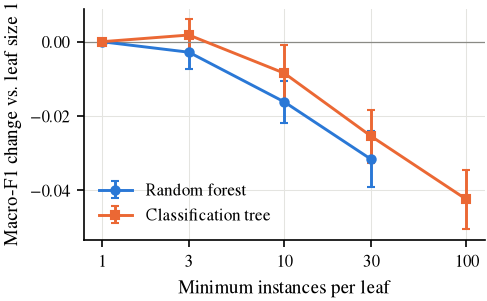

In [27]:
forest_leaf = []
for fold, output in enumerate(fold_outputs["Random forest"]):
    tuning = output["tuning"]
    best1 = tuning.query("stage == 1").sort_values("macro_f1").iloc[-1]
    curve = pd.concat([best1.to_frame().T, tuning.query("stage == 2")])
    curve["min_samples_leaf"] = curve["min_samples_leaf"].astype(int)
    forest_leaf.append(curve.set_index("min_samples_leaf")["macro_f1"].astype(float).rename(fold + 1))
forest_leaf = pd.concat(forest_leaf, axis=1)

tree_tuning = pd.concat(
    [output["tuning"].assign(fold=fold + 1) for fold, output in enumerate(fold_outputs["Classification tree"])],
    ignore_index=True)
tree_tuning.to_csv(TABLE_DIR / "tree_tuning_all_folds.csv", index=False)
tree_leaf = tree_tuning.groupby(["min_samples_leaf", "fold"])["macro_f1"].max().unstack("fold")

rq2 = pd.DataFrame({
    "forest_mean": forest_leaf.mean(axis=1), "forest_std": forest_leaf.std(axis=1),
    "tree_mean": tree_leaf.mean(axis=1), "tree_std": tree_leaf.std(axis=1),
})
rq2.to_csv(TABLE_DIR / "rq2_leaf_size.csv")
display(rq2.round(4))

fig, ax = plt.subplots(figsize=(COLUMN_WIDTH, 2.0))
for model, table in [("Random forest", forest_leaf), ("Classification tree", tree_leaf)]:
    relative = table - table.loc[1]
    ax.errorbar(relative.index, relative.mean(axis=1), yerr=relative.std(axis=1),
                marker=MODEL_MARKERS[model], color=MODEL_COLOURS[model], label=model, capsize=2)
ax.axhline(0, color="#8a8a85", linewidth=0.6)
ax.set_xscale("log")
ax.set_xticks(tree_leaf.index, [str(v) for v in tree_leaf.index])
ax.minorticks_off()
ax.set_xlabel("Minimum instances per leaf")
ax.set_ylabel("Macro-F1 change vs. leaf size 1")
ax.legend(loc="lower left")
save_figure(fig, "rq2_leaf_size")
plt.show()

### 6.7 RQ3 and RQ6: class weighting, overall and per class

The kNN rows answer RQ6; the weights are taken at the fold's best number of
neighbours and vote type.

The per-class change in evaluation-set F1 compared with no weighting is
taken at each fold's best `max_features` (forest) or the best
criterion and leaf size (tree), then averaged over folds.

In [28]:
f1_columns = [f"f1_{c}" for c in CLASSES]


def weighting_effect(tuning, keys):
    best = tuning.loc[tuning["macro_f1"].idxmax()]
    rows = tuning
    for key in keys:
        rows = rows[rows[key] == best[key]]
    rows = rows.set_index("class_weight")
    return rows.loc[WEIGHT_ORDER, ["macro_f1"] + f1_columns]


forest_weighting = pd.concat(
    [weighting_effect(o["tuning"].query("stage == 1"), ["max_features"]).assign(fold=f + 1)
     for f, o in enumerate(fold_outputs["Random forest"])])
tree_weighting = pd.concat(
    [weighting_effect(o["tuning"], ["criterion", "min_samples_leaf"]).assign(fold=f + 1)
     for f, o in enumerate(fold_outputs["Classification tree"])])
knn_weighting = pd.concat(
    [weighting_effect(o["tuning"], ["n_neighbors", "vote"]).assign(fold=f + 1)
     for f, o in enumerate(fold_outputs["Class-weighted k-nearest neighbours"])])

rq3_rows = []
for model, table in [("Random forest", forest_weighting), ("Classification tree", tree_weighting),
                     ("Class-weighted k-nearest neighbours", knn_weighting)]:
    baseline = table.loc["none"].set_index("fold")
    for scheme in ["sqrt", "balanced"]:
        delta = table.loc[scheme].set_index("fold") - baseline
        row = {"model": model, "scheme": scheme, "macro_f1": delta["macro_f1"].mean(),
               "macro_f1_wins": int((delta["macro_f1"] > 0).sum())}
        row.update({CLASS_NAMES[c]: delta[f"f1_{c}"].mean() for c in CLASSES})
        rq3_rows.append(row)
rq3 = pd.DataFrame(rq3_rows)
rq3.to_csv(TABLE_DIR / "rq3_class_weighting.csv", index=False)
rq3.round(4)

,model,scheme,macro_f1,macro_f1_wins,Normal,Reconnaissance,Backdoor,DoS,Exploits,Analysis,Fuzzers,Worms,Shellcode,Generic
0,Random forest,sqrt,0.0230,10,-0.0042,0.0019,-0.0187,0.1194,-0.0195,-0.0263,0.0205,0.1304,0.0266,-0.0000
1,Random forest,balanced,-0.0162,0,-0.0240,-0.0033,-0.1253,-0.0115,-0.0406,-0.1185,0.0160,0.1416,0.0048,-0.0009
2,Classification tree,sqrt,0.0186,10,-0.0016,0.0011,0.0056,0.0853,-0.0173,-0.0123,0.0119,0.0940,0.0192,0.0002
3,Classification tree,balanced,-0.0186,0,-0.0053,-0.0036,-0.0969,-0.0470,-0.0437,-0.1060,0.0247,0.0623,0.0294,0.0000
4,Class-weighted k-nearest neighbours,sqrt,-0.0138,2,-0.0112,-0.0007,0.0231,0.0156,-0.0397,-0.0466,0.0337,-0.0247,-0.0873,0.0002
5,Class-weighted k-nearest neighbours,balanced,-0.0367,0,-0.0249,-0.0469,0.0090,-0.0275,-0.0745,-0.0683,0.0314,-0.0349,-0.1311,0.0004


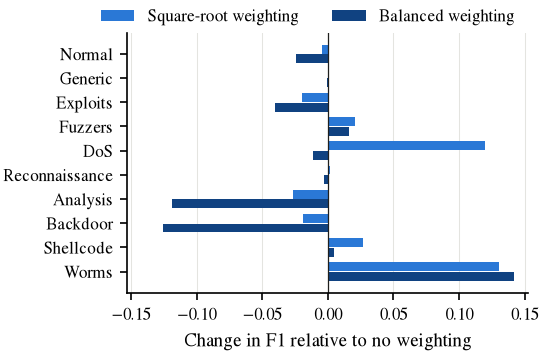

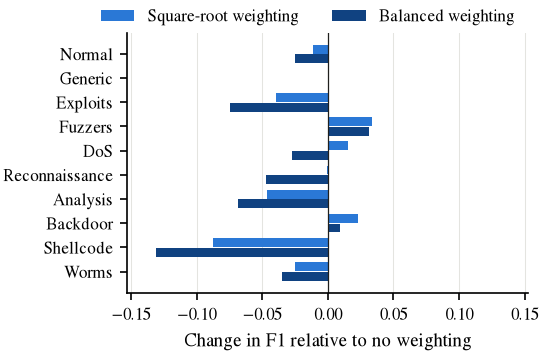

In [29]:
positions = np.arange(len(class_order))[::-1]
limit = 1.08 * rq3[class_order].abs().to_numpy().max()
for name, model in [("rq3_forest", "Random forest"),
                    ("rq3_knn", "Class-weighted k-nearest neighbours")]:
    fig, ax = plt.subplots(figsize=(COLUMN_WIDTH, 2.25))
    for offset, scheme in zip([0.2, -0.2], ["sqrt", "balanced"]):
        values = rq3.query("model == @model and scheme == @scheme")[class_order].iloc[0]
        ax.barh(positions + offset, values, height=0.37, color=WEIGHT_COLOURS[scheme],
                label=WEIGHT_LABELS[scheme])
    ax.axvline(0, color="#1f1f1d", linewidth=0.6)
    ax.set_xlim(-limit, limit)
    ax.set_yticks(positions, class_order)
    ax.set_xlabel("Change in F1 relative to no weighting")
    ax.grid(axis="y", visible=False)
    ax.legend(loc="upper center", bbox_to_anchor=(0.45, 1.15), ncol=2)
    save_figure(fig, name)
    plt.show()

### 6.8 RQ4: number of trees

Test-fold macro-F1 of the final 300-tree forests as trees are added, in the
order they were grown. The shaded band is ±1 standard deviation over the
ten folds.

Trees needed to come within 0.005 of the 300-tree macro-F1: 20
Trees needed to come within 0.001: 75


,1,2,3,5,10,15,20,30,40,50,75,100,150,200,250,300
mean,0.5706,0.5745,0.6016,0.6100,0.6169,0.6227,0.6253,0.6274,0.6268,0.6275,0.6279,0.6285,0.6291,0.6284,0.6289,0.6287
std,0.0077,0.0118,0.0073,0.0093,0.0100,0.0099,0.0091,0.0086,0.0100,0.0100,0.0104,0.0096,0.0087,0.0091,0.0089,0.0097


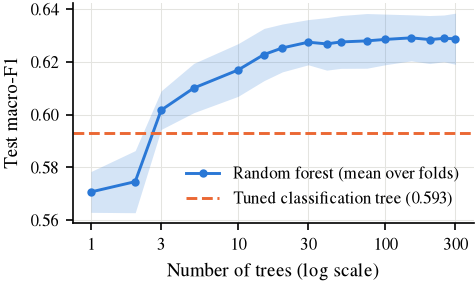

In [30]:
tree_curves = pd.DataFrame({fold + 1: output["tree_curve"]
                            for fold, output in enumerate(fold_outputs["Random forest"])})
tree_curves.to_csv(TABLE_DIR / "rq4_tree_curve.csv")
curve_mean, curve_std = tree_curves.mean(axis=1), tree_curves.std(axis=1)
final_value = curve_mean.iloc[-1]
within = curve_mean[curve_mean >= final_value - 0.005]
print("Trees needed to come within 0.005 of the 300-tree macro-F1:", within.index.min())
print("Trees needed to come within 0.001:", curve_mean[curve_mean >= final_value - 0.001].index.min())
display(pd.DataFrame({"mean": curve_mean, "std": curve_std}).round(4).T)

fig, ax = plt.subplots(figsize=(COLUMN_WIDTH, 1.9))
ax.plot(curve_mean.index, curve_mean, color=MODEL_COLOURS["Random forest"], marker="o",
        markersize=3, label="Random forest (mean over folds)")
ax.fill_between(curve_mean.index, curve_mean - curve_std, curve_mean + curve_std,
                color=MODEL_COLOURS["Random forest"], alpha=0.2, linewidth=0)
tree_mean = fold_results.query("model == 'Classification tree'")["macro_f1"].mean()
ax.axhline(tree_mean, color=MODEL_COLOURS["Classification tree"], linestyle="--",
           label=f"Tuned classification tree ({tree_mean:.3f})")
ax.set_xscale("log")
ax.set_xticks([1, 3, 10, 30, 100, 300], ["1", "3", "10", "30", "100", "300"])
ax.minorticks_off()
ax.set_xlabel("Number of trees (log scale)")
ax.set_ylabel("Test macro-F1")
ax.legend(loc="lower right")
save_figure(fig, "rq4_number_of_trees")
plt.show()

### 6.9 RQ5: ordinal versus one-hot encoding

In [31]:
encoding_rows = []
for model, key in [("Random forest", "Random forest"), ("Classification tree", "Classification tree")]:
    for fold, output in enumerate(fold_outputs[key]):
        encoding_rows.append(output["encoding"].assign(model=model, fold=fold + 1))
encoding = pd.concat(encoding_rows, ignore_index=True)
rq5 = encoding.groupby(["model", "encoding"])[["n_columns", "macro_f1", "fit_seconds"]].agg(["mean", "std"])
rq5.to_csv(TABLE_DIR / "rq5_encoding.csv")
display(rq5.round(4))
for model in ["Random forest", "Classification tree"]:
    wide = encoding.query("model == @model").pivot(index="fold", columns="encoding", values="macro_f1")
    print(model, "ordinal - one-hot:", round((wide["ordinal"] - wide["onehot"]).mean(), 4),
          "| ordinal wins", int((wide["ordinal"] > wide["onehot"]).sum()), "of", N_FOLDS,
          "| Wilcoxon p =", round(stats.wilcoxon(wide["ordinal"], wide["onehot"]).pvalue, 4))

n_columns         macro_f1         fit_seconds        
                                  mean     std     mean     std        mean     std
model               encoding                                                       
Classification tree onehot       193.9  0.9944   0.5785  0.0119      5.9096  0.7327
                    ordinal       42.0  0.0000   0.5726  0.0072      4.2551  0.7678
Random forest       onehot       193.9  0.9944   0.5552  0.0094     19.3920  5.9903
                    ordinal       42.0  0.0000   0.5726  0.0110     17.6257  5.2895

Random forest ordinal - one-hot: 0.0175 | ordinal wins 10 of 10 | Wilcoxon p = 0.002
Classification tree ordinal - one-hot: -0.0059 | ordinal wins 3 of 10 | Wilcoxon p = 0.0273


### 6.10 Feature importance

The mean decrease in impurity (MDI) is averaged over the ten final forests.
Permutation importance (the macro-F1 decrease on held-out data when one
feature is shuffled) is averaged over the five folds of the first
repetition. MDI is biased towards features with many distinct values and
is computed on training data, so the permutation measure is the primary one.
Shuffling one feature of a correlated group understates that group's
importance, because the remaining features carry the same information.

,mdi,permutation
sbytes,0.2411,0.2972
sttl,0.1303,0.1946
service,0.0479,0.1446
smean,0.0768,0.1280
ct_dst_src_ltm,0.0307,0.0766
ct_srv_dst,0.0394,0.0437
dbytes,0.0482,0.0427
dmean,0.0257,0.0295
ct_srv_src,0.0183,0.0253
proto,0.0178,0.0153


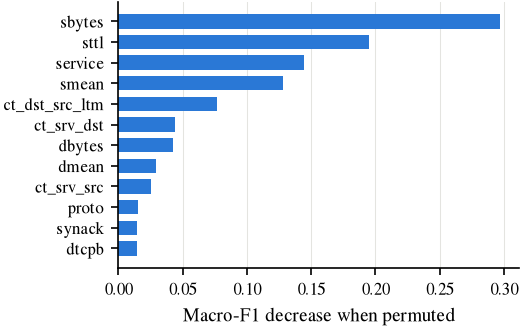

In [32]:
forest_outputs = fold_outputs["Random forest"]
names = forest_outputs[0]["feature_names"]
importance = pd.DataFrame({
    "mdi": np.mean([o["mdi_importance"] for o in forest_outputs], axis=0),
    "permutation": np.mean([o["permutation_importance"] for o in forest_outputs
                            if "permutation_importance" in o], axis=0),
}, index=names).sort_values("permutation", ascending=False)
importance.to_csv(TABLE_DIR / "feature_importance.csv")
display(importance.head(15).round(4))

top = importance.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(COLUMN_WIDTH, 2.3))
ax.barh(np.arange(len(top)), top["permutation"], color="#2a78d6", height=0.7)
ax.set_yticks(np.arange(len(top)), top.index)
ax.set_xlabel("Macro-F1 decrease when permuted")
ax.grid(axis="y", visible=False)
save_figure(fig, "feature_importance")
plt.show()

### 6.11 Computational cost

In [33]:
cost = pd.DataFrame([
    {"model": model, "fold": fold + 1, "seconds": output["seconds"]}
    for model in MODEL_ORDER for fold, output in enumerate(fold_outputs[model])
]).groupby("model")["seconds"].agg(["mean", "std"]).reindex(MODEL_ORDER)
cost["final_forest_fit_seconds"] = np.nan
cost.loc["Random forest", "final_forest_fit_seconds"] = np.mean(
    [o["final_fit_seconds"] for o in forest_outputs])
cost.to_csv(TABLE_DIR / "computational_cost.csv")
cost.round(1)

,mean,std,final_forest_fit_seconds
model,,,
Random forest,1305.9,394.1,211.6
Classification tree,179.7,43.0,NaN
Class-weighted k-nearest neighbours,369.5,21.3,NaN
k-nearest neighbours,1072.8,81.6,NaN


## 7. Final model on all data

Cross-validation estimates how well the *procedure* generalises. The model
to deploy is fitted on all available data, using the configuration that was
selected most often across the ten folds.

For an ordinary forest, the out-of-bag (OOB) estimate would give a further
check without held-out data: each instance is predicted only by the trees
whose bootstrap excluded it (about 37% of trees). With the class-weighted
bootstrap that check breaks down. Rare-class instances are drawn with high
probability (a *Worms* instance has weight 12), so they are almost never out
of bag. The cell reports OOB coverage per class and OOB metrics on covered
instances only. Those metrics under-represent the rare classes, so the
cross-validated estimate above remains the primary result.

In [34]:
forest_selected = selected.query("model == 'Random forest'")[
    ["max_features", "min_samples_leaf", "class_weight"]]
# The most frequently selected configuration; ties are broken by the mean
# evaluation-set macro-F1 of the folds that selected each configuration.
forest_choices = forest_selected.assign(
    eval_macro_f1=fold_results.query("model == 'Random forest'")["eval_macro_f1"].to_numpy())
choice_summary = forest_choices.groupby(["max_features", "min_samples_leaf", "class_weight"])[
    "eval_macro_f1"].agg(["size", "mean"]).sort_values(["size", "mean"], ascending=False)
display(choice_summary)
best_choice = choice_summary.index[0]
final_params = {"max_features": float(best_choice[0]), "min_samples_leaf": int(best_choice[1]),
                "class_weight": best_choice[2]}
print("Final configuration:", final_params)


def fit_final_forest():
    pre = make_tree_preprocessor().fit(X)
    X_all = encode(pre, np.arange(len(X)))
    forest = make_forest(final_params, y, RF_FINAL_TREES, RANDOM_STATE)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", UserWarning)
        forest.set_params(oob_score=True).fit(X_all, y)
    decision = np.nan_to_num(forest.oob_decision_function_)
    covered = decision.sum(axis=1) > 0
    oob_pred = forest.classes_[decision[covered].argmax(axis=1)]
    return {"params": final_params,
            "oob_coverage": {CLASS_NAMES[c]: covered[y == c].mean() for c in CLASSES},
            "oob_metrics": calculate_metrics(y[covered], oob_pred),
            "oob_per_class_f1": per_class_f1(y[covered], oob_pred)}


final_model = cached("final_forest", 0, fit_final_forest)
display(pd.Series(final_model["oob_coverage"], name="share of instances with an OOB prediction").round(3))
pd.Series(final_model["oob_metrics"], name="OOB metrics on covered instances").round(4)

size      mean
max_features min_samples_leaf class_weight                
0.75         1.0              sqrt             4  0.628052
0.50         1.0              sqrt             4  0.625393
             3.0              sqrt             2  0.623770

Final configuration: {'max_features': 0.75, 'min_samples_leaf': 1, 'class_weight': 'sqrt'}


Normal            1.000
Reconnaissance    1.000
Backdoor          0.995
DoS               1.000
Exploits          1.000
Analysis          0.998
Fuzzers           1.000
Worms             0.000
Shellcode         0.864
Generic           1.000
Name: share of instances with an OOB prediction, dtype: float64

accuracy             0.8227
balanced_accuracy    0.6168
macro_f1             0.5504
weighted_f1          0.8299
Name: OOB metrics on covered instances, dtype: float64

## 8. Comparison with the published Assignment 2 results

The Assignment 2 report used different outer folds (one repetition of
5-fold cross-validation), so its numbers are not paired with the results
above. They are listed for context only.

In [35]:
assignment2 = pd.DataFrame({
    "accuracy": [0.801, 0.795], "balanced_accuracy": [0.577, 0.498],
    "macro_f1": [0.562, 0.517], "weighted_f1": [0.799, 0.791],
}, index=["Classification tree (A2)", "k-nearest neighbours (A2)"])
current = summary.xs("mean", axis=1, level=1).loc[MODEL_ORDER]
pd.concat([current, assignment2]).round(3)

,accuracy,balanced_accuracy,macro_f1,weighted_f1
Random forest,0.823,0.647,0.629,0.830
Classification tree,0.801,0.611,0.593,0.808
Class-weighted k-nearest neighbours,0.790,0.516,0.515,0.789
k-nearest neighbours,0.793,0.501,0.519,0.790
Classification tree (A2),0.801,0.577,0.562,0.799
k-nearest neighbours (A2),0.795,0.498,0.517,0.791
